# Case 1 — notebook_3: Post-mortem notebook_2 + Pipeline Terkoreksi

`notebook_2` **gagal**. CV membaik (0,1826 → 0,1789) tapi LB memburuk jauh
(0,2005 → **0,2262**). Estimasi LB terkoreksi yang saya pakai di notebook_2 (0,1902)
meleset +0,036 — jadi metode estimasinya juga ikut salah.

Notebook ini mencari penyebabnya, lalu memperbaiki pipeline berdasarkan temuan itu.

## Riwayat leaderboard

| Submission | CV | Estimasi LB | **LB aktual** |
|---|---|---|---|
| notebook_1 | 0,1826 | 0,1953 | **0,2005** |
| notebook_2 | 0,1789 | 0,1902 | **0,2262** ❌ |
| notebook_3 (ini) | 0,1855 | — | ? |

## Penyebabnya: model menghafal prior katalog, bukan fisika

Di train, tipe depth berkorelasi kuat dengan magnitudo:

| Subset train | n | mean magnitudo |
|---|---|---|
| depth desimal | 7.195 | **5,192** |
| depth bulat < 100 km | 3.044 | **5,453** |
| depth bulat ≥ 100 km | 266 | 5,755 |

Selisih 0,26 magnitudo antara record depth-bulat dan depth-desimal. Itu **artefak katalog**
(gempa yang kedalamannya tidak terselesaikan diberi nilai default), bukan hukum fisika.

Masking di `notebook_2` justru memberi model **indikator sempurna** untuk tipe depth
(`grp_size = NaN` ⟺ depth bulat). Model memakainya untuk menerapkan prior train tadi, dan
karena bobot metrik menaikkan gempa besar 2,5×, menaikkan prediksi subset depth-bulat
**memperbaiki CV**.

Masalahnya: **komposisi test berbeda** — depth bulat mengisi 32% train tapi 51% test. Prior
train tidak berlaku di sana, jadi model sistematis menebak terlalu tinggi.

## Diagnostik baru: `bias_rnd`

Bias OOF pada subset depth-bulat ternyata memprediksi kegagalan LB jauh lebih baik daripada CV:

| Submission | CV | `bias_rnd` | LB |
|---|---|---|---|
| notebook_1 | 0,1824 | +0,076 | 0,2005 |
| notebook_2 | 0,1798 | **+0,137** | 0,2262 |

CV turun 0,003 sementara LB naik 0,026 — sementara `bias_rnd` bergerak searah LB.
**Mulai sekarang tiap kandidat dinilai dengan CV *dan* `bias_rnd`.**

## Perbaikan di notebook ini

Ekspansi varians global ternyata ikut memperbesar bias: subset depth-bulat rata-ratanya di
atas mean keseluruhan, jadi dikalikan `alpha` ia terdorong makin ke atas. Solusinya
**memusatkan ekspansi per subset**, sehingga varians tetap dikembalikan tanpa menggeser
rata-rata subset. `bias_rnd` turun +0,076 → **+0,046** dengan ongkos CV hanya 0,003.

---
## 1. Setup

In [1]:
import numpy as np, pandas as pd, time, sys, warnings, json
warnings.filterwarnings("ignore")
from pathlib import Path
from scipy import signal, stats
from sklearn.model_selection import GroupKFold
import lightgbm as lgb
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110; pd.set_option("display.width", 200)

DATA = Path("seismic-dataset"); SUB = Path("submission"); SUB.mkdir(exist_ok=True)
FS, P_IDX, EPS = 200, 200, 1e-15

train = (pd.read_csv(DATA/"train"/"train_meta.csv")
           .merge(pd.read_csv(DATA/"train"/"train_labels.csv"), on="sample_id"))
test  = pd.read_csv(DATA/"test"/"test_meta.csv")
y  = train.magnitude.values.astype(np.float64)
ev = train.groupby(["depth_km","magnitude"]).ngroup().values
cnt = pd.Series(ev).map(pd.Series(ev).value_counts()).values

def mag_weight(m):
    m=np.asarray(m); return np.where(m<5.5,1.0,np.where(m<6.0,1.5,np.where(m<6.5,2.0,2.5)))
def eb_twmae(yt,yp,e):
    df=pd.DataFrame({"y":yt,"p":yp,"e":e}); df["err"]=np.abs(df.y-df.p)
    g=df.groupby("e").agg(mae=("err","mean"),m=("y","first"))
    w=mag_weight(g.m.values); return float((w*g.mae.values).sum()/w.sum())

SW = mag_weight(y)/cnt
d_tr = train.depth_km.values; d_te = test.depth_km.values
rnd_tr = np.isclose(d_tr, np.round(d_tr)); rnd_te = np.isclose(d_te, np.round(d_te))

---
## 2. Bukti: Prior Katalog yang Tidak Bisa Ditransfer

Sebelum memperbaiki apapun, buktikan dulu mekanismenya.

In [2]:
rows=[]
for lbl, m in [("depth desimal", ~rnd_tr),
               ("depth bulat < 100 km", rnd_tr & (d_tr<100)),
               ("depth bulat >= 100 km", rnd_tr & (d_tr>=100))]:
    rows.append(dict(subset=lbl, n_train=int(m.sum()), mean_magnitudo=round(y[m].mean(),3)))
display(pd.DataFrame(rows))

print("proporsi record depth-bulat:  train %.0f%%   test %.0f%%" %
      (rnd_tr.mean()*100, rnd_te.mean()*100))
print()
print("Tipe depth memprediksi magnitudo di train (selisih %.2f), tapi proporsinya"
      % (y[rnd_tr & (d_tr<100)].mean() - y[~rnd_tr].mean()))
print("berbeda jauh di test -> prior itu tidak bisa ditransfer.")

,subset,n_train,mean_magnitudo
0,depth desimal,7195,5.192
1,depth bulat < 100 km,3044,5.453
2,depth bulat >= 100 km,266,5.755


proporsi record depth-bulat:  train 32%   test 51%

Tipe depth memprediksi magnitudo di train (selisih 0.26), tapi proporsinya
berbeda jauh di test -> prior itu tidak bisa ditransfer.


Inilah jebakannya. Setiap fitur yang membuat model bisa **mengenali tipe depth** memberi
jalan pintas: naikkan prediksi untuk depth bulat. Jalan pintas itu berbayar di CV (karena
train memang begitu) dan merugi di LB (karena test komposisinya lain).

`notebook_2` memasang jalan pintas paling terang-terangan — `NaN` sebagai penanda tipe depth.

---
## 3. Fitur & Model

Ekstraksi fitur identik `notebook_1`/`notebook_2` (196 fitur). Model B memakai fitur agregat
grup versi **penuh** (tanpa masking) — persis `notebook_1`.

In [3]:
def _hp(a,f=0.075,order=2):
    b,aa=signal.butter(order,f/(FS/2),btype="high")
    return signal.filtfilt(b,aa,a,axis=1).astype(np.float32)
def L(x): return np.log10(np.abs(x)+EPS).astype(np.float32)
WINS=[0.25,0.5,1.0,1.5,2.0,3.0,4.0]

def extract(X, meta, verbose=True):
    t0=time.time(); out={}
    A=X.astype(np.float32); V=np.cumsum(_hp(A),axis=1)/FS; D=np.cumsum(_hp(V),axis=1)/FS
    def hv(W): return np.sqrt(W[:,:,0]**2+W[:,:,1]**2), np.abs(W[:,:,2])
    for nm,W in [("a",A),("v",V),("d",D)]:
        H,Vt=hv(W); allc=np.abs(W).max(axis=2)
        for s in WINS:
            n=int(s*FS)
            out[f"P{nm}_{s:g}"]=L(allc[:,P_IDX:P_IDX+n].max(1))
            out[f"P{nm}H_{s:g}"]=L(H[:,P_IDX:P_IDX+n].max(1))
            out[f"P{nm}V_{s:g}"]=L(Vt[:,P_IDX:P_IDX+n].max(1))
        out[f"pre_{nm}"]=L(allc[:,:P_IDX].max(1))
        out[f"snr_{nm}"]=out[f"P{nm}_4"]-out[f"pre_{nm}"]
        for s in [1.0,2.0,4.0]:
            n=int(s*FS)
            out[f"rms{nm}_{s:g}"]=L(np.sqrt((W[:,P_IDX:P_IDX+n,:]**2).mean(axis=(1,2))))
        out[f"hv_{nm}"]=L(H[:,P_IDX:].max(1))-L(Vt[:,P_IDX:].max(1))
    e=(A[:,P_IDX:,:]**2).sum(axis=2); ce=np.cumsum(e,axis=1); tot=ce[:,-1:]+EPS
    frac=ce/tot; out["logE"]=L(tot[:,0])
    for q in [0.1,0.25,0.5,0.75,0.9]:
        out[f"tE{int(q*100)}"]=(np.argmax(frac>=q,axis=1)/FS).astype(np.float32)
    out["E_slope"]=(out["tE90"]-out["tE10"]).astype(np.float32)
    for nm,W in [("a",A),("d",D)]:
        ab=np.abs(W[:,P_IDX:,:]).max(axis=2); tp=ab.argmax(axis=1)/FS
        out[f"tpk_{nm}"]=tp.astype(np.float32)
        out[f"rise_{nm}"]=(L(ab.max(1))/(tp+0.05)).astype(np.float32)
    n3=600
    num=(V[:,P_IDX:P_IDX+n3,:]**2).sum(1); den=(D[:,P_IDX:P_IDX+n3,:]**2).sum(1)
    out["tauc"]=L(2*np.pi*np.sqrt((den/(num+1e-30)).mean(1)))
    for s in [1.0,2.0]:
        n=int(s*FS); nu=(V[:,P_IDX:P_IDX+n,:]**2).sum(1)
        dv=np.gradient(V[:,P_IDX:P_IDX+n,:],1/FS,axis=1)
        out[f"taup_{s:g}"]=L(2*np.pi*np.sqrt((nu/((dv**2).sum(1)+1e-30)).mean(1)))
    for nm,W in [("a",A),("d",D)]:
        f,Pxx=signal.welch(W[:,P_IDX:,:],fs=FS,nperseg=256,axis=1)
        Pm=Pxx.mean(axis=2); tote=Pm.sum(1)+EPS
        for lo,hi in [(0.1,1),(1,3),(3,5),(5,10),(10,20),(20,50),(50,100)]:
            m=(f>=lo)&(f<hi)
            out[f"bd{nm}_{lo:g}_{hi:g}"]=L(Pm[:,m].sum(1))
            out[f"bdr{nm}_{lo:g}_{hi:g}"]=(Pm[:,m].sum(1)/tote).astype(np.float32)
        out[f"cent_{nm}"]=((Pm*f).sum(1)/tote).astype(np.float32)
        out[f"fdom_{nm}"]=f[Pm.argmax(1)].astype(np.float32)
        out[f"lhr_{nm}"]=L(Pm[:,(f>=0.1)&(f<3)].sum(1))-L(Pm[:,(f>=10)&(f<50)].sum(1))
    seg=A[:,P_IDX:,:]
    out["kurt"]=stats.kurtosis(seg,axis=1).mean(1).astype(np.float32)
    out["skew"]=np.abs(stats.skew(seg,axis=1)).mean(1).astype(np.float32)
    out["zcr"]=(np.diff(np.sign(seg),axis=1)!=0).mean(axis=(1,2)).astype(np.float32)
    Sg=seg-seg.mean(1,keepdims=True)
    evl=np.linalg.eigvalsh(np.einsum("nti,ntj->nij",Sg,Sg)/Sg.shape[1])
    evl=np.maximum(evl,0)+1e-30
    out["rectilin"]=(1-(evl[:,0]+evl[:,1])/(2*evl[:,2])).astype(np.float32)
    out["planarity"]=(1-2*evl[:,0]/(evl[:,1]+evl[:,2])).astype(np.float32)
    F=pd.DataFrame(out)
    dist=meta.distance_km.values.astype(np.float32); dep=meta.depth_km.values.astype(np.float32)
    F["distance_km"]=dist; F["depth_km"]=dep
    F["snr_db"]=meta.snr_db.values.astype(np.float32)
    F["is_clipped"]=meta.is_clipped.values.astype(np.int8)
    F["logdist"]=np.log10(dist+1); F["logdep"]=np.log10(dep+1)
    F["hypo"]=np.sqrt(dist**2+dep**2); F["loghypo"]=np.log10(F.hypo+1)
    for nm in ["a","v","d"]:
        for s in WINS:
            F[f"C{nm}_{s:g}"]=F[f"P{nm}_{s:g}"]+F["loghypo"]
            F[f"C{nm}d_{s:g}"]=F[f"P{nm}_{s:g}"]+1.5*F["logdist"]
        for s1,s2 in [(0.5,1.0),(1.0,2.0),(2.0,4.0),(0.5,4.0)]:
            F[f"g{nm}_{s1:g}_{s2:g}"]=F[f"P{nm}_{s2:g}"]-F[f"P{nm}_{s1:g}"]
    if verbose: print("  %.1fs -> %d fitur"%(time.time()-t0,F.shape[1]))
    return F.astype(np.float32)

AGG_SRC=["Pd_1","Pd_2","Pd_4","Pv_2","Pv_4","Pa_4","Cd_2","Cd_4","Cv_2","Ca_4",
         "logE","rmsd_2","lhr_a","cent_a","tauc","logdist","loghypo","snr_db",
         "gd_0.5_4","gv_1_2","PdH_2","PdV_2"]
def add_group_feats(F, meta):
    G=F.copy(); key=meta.depth_km.values; k=pd.Series(key)
    G["grp_size"]=k.map(k.value_counts()).values.astype(np.float32)
    for c in AGG_SRC:
        s=pd.Series(F[c].values)
        gm=s.groupby(key).transform("mean").values
        gx=s.groupby(key).transform("max").values
        gn=s.groupby(key).transform("min").values
        G[f"gm_{c}"]=gm.astype(np.float32)
        G[f"gd_{c}"]=(F[c].values-gm).astype(np.float32)
        G[f"gs_{c}"]=s.groupby(key).transform("std").fillna(0).values.astype(np.float32)
        G[f"gx_{c}"]=gx.astype(np.float32)
        G[f"gr_{c}"]=(gx-gn).astype(np.float32)
    return G.astype(np.float32)

print("TRAIN"); Ftr=extract(np.load(DATA/"train"/"train_waveforms.npy"), train)
print("TEST ");  Fte=extract(np.load(DATA/"test"/"test_waveforms.npy"), test)
Gtr=add_group_feats(Ftr,train); Gte=add_group_feats(Fte,test)

TRAIN


  7.7s -> 196 fitur
TEST 


  1.6s -> 196 fitur


In [4]:
PARAMS=dict(objective="mae",learning_rate=0.02,num_leaves=31,min_child_samples=50,
            subsample=0.8,subsample_freq=1,colsample_bytree=0.7,reg_lambda=1.0,
            n_jobs=-1,verbose=-1)
NFOLD,SEEDS=5,(0,1,2)
def cv_lgb(Xtr,Xte=None,sw=SW,seeds=SEEDS):
    oof=np.zeros(len(y)); pte=np.zeros(len(Xte)) if Xte is not None else None
    for seed in seeds:
        o=np.zeros(len(y))
        for ti,vi in GroupKFold(n_splits=NFOLD).split(Xtr,y,ev):
            p=dict(PARAMS); p["seed"]=seed
            m=lgb.LGBMRegressor(n_estimators=4000,**p)
            m.fit(Xtr.iloc[ti],y[ti],sample_weight=sw[ti],
                  eval_set=[(Xtr.iloc[vi],y[vi])],eval_sample_weight=[sw[vi]],
                  callbacks=[lgb.early_stopping(200,verbose=False)])
            o[vi]=m.predict(Xtr.iloc[vi])
            if Xte is not None: pte+=m.predict(Xte)/(NFOLD*len(seeds))
        oof+=o/len(seeds)
    return oof,pte

t0=time.time(); oofA,pteA=cv_lgb(Ftr,Fte); print("A: %.4f (%.0fs)"%(eb_twmae(y,oofA,ev),time.time()-t0))
t0=time.time(); oofB,pteB=cv_lgb(Gtr,Gte); print("B: %.4f (%.0fs)"%(eb_twmae(y,oofB,ev),time.time()-t0))

A: 0.2160 (62s)


B: 0.2057 (72s)


---
## 4. Dua Diagnostik Wajib

Selain CV, tiap kandidat sekarang diukur dengan **`bias_rnd`** — bias OOF pada subset
depth-bulat. Inilah yang menangkap seberapa jauh sebuah pipeline bersandar pada prior
katalog yang tidak bisa ditransfer.

In [5]:
MR = rnd_tr & (d_tr < 100)      # subset depth-bulat train
MT = rnd_te & (d_te < 100)      # subset yang sama di test

def bias_rnd(p):  return float(p[MR].mean() - y[MR].mean())
def test_rnd(p):  return float(p[MT].mean())

def smooth(p, dep, lam=0.95):
    '''Median per grup depth, hanya untuk depth desimal (Jensen; lihat notebook_1).'''
    r = np.isclose(dep, np.round(dep))
    gm = pd.Series(p).groupby(pd.Series(dep)).transform("median").values
    return np.where(r, p, (1-lam)*p + lam*gm)

def expand_global(p, dep, a):
    return p.mean() + a*(p - p.mean())

def expand_subset(p, dep, a):
    '''Ekspansi dipusatkan per subset -> varians kembali tanpa menggeser mean subset.'''
    r = np.isclose(dep, np.round(dep)); q = p.copy()
    for m in (r, ~r):
        mu = p[m].mean(); q[m] = mu + a*(p[m]-mu)
    return q

In [6]:
W_B, LAM = 0.35, 0.95
blend_o = (1-W_B)*oofA + W_B*oofB
blend_p = (1-W_B)*pteA + W_B*pteB
sm_o, sm_p = smooth(blend_o, d_tr, LAM), smooth(blend_p, d_te, LAM)

rows=[]
for exn, exf in [("global", expand_global), ("per-subset", expand_subset)]:
    for a in [1.00, 1.05, 1.10, 1.15, 1.20]:
        o = exf(sm_o, d_tr, a)
        rows.append(dict(ekspansi=exn, alpha=a, CV=round(eb_twmae(y,o,ev),4),
                         bias_rnd=round(bias_rnd(o),3),
                         test_rnd=round(test_rnd(exf(sm_p,d_te,a)),3)))
R = pd.DataFrame(rows)
display(R)

,ekspansi,alpha,CV,bias_rnd,test_rnd
0,global,1.00,0.1904,0.048,5.285
1,global,1.05,0.1859,0.058,5.287
2,global,1.10,0.1834,0.067,5.290
3,global,1.15,0.1826,0.077,5.293
4,global,1.20,0.1838,0.086,5.296
5,per-subset,1.00,0.1904,0.048,5.285
6,per-subset,1.05,0.1873,0.048,5.282
7,per-subset,1.10,0.1857,0.047,5.279
8,per-subset,1.15,0.1855,0.047,5.276
9,per-subset,1.20,0.1868,0.046,5.273


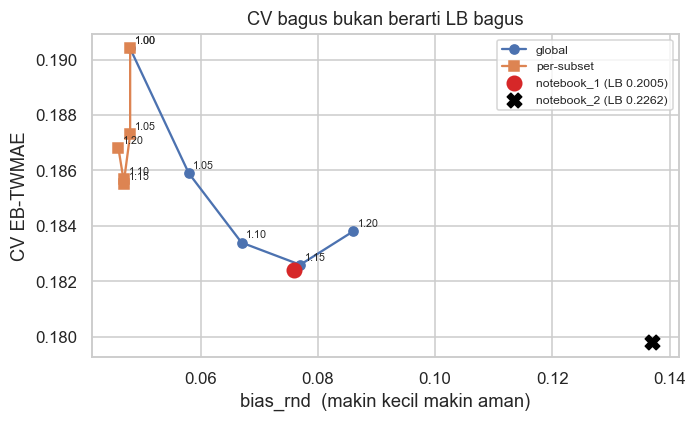

In [7]:
fig, ax = plt.subplots(figsize=(6.5,4))
for exn, mk in [("global","o"),("per-subset","s")]:
    s = R[R.ekspansi==exn]
    ax.plot(s.bias_rnd, s.CV, marker=mk, label=exn)
    for _,row in s.iterrows():
        ax.annotate(f"{row.alpha:.2f}", (row.bias_rnd, row.CV), fontsize=7,
                    xytext=(3,3), textcoords="offset points")
ax.scatter([0.076],[0.1824], color="tab:red", s=90, zorder=5, label="notebook_1 (LB 0.2005)")
ax.scatter([0.137],[0.1798], color="black", s=90, marker="X", zorder=5, label="notebook_2 (LB 0.2262)")
ax.set_xlabel("bias_rnd  (makin kecil makin aman)"); ax.set_ylabel("CV EB-TWMAE")
ax.set_title("CV bagus bukan berarti LB bagus")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Grafik ini merangkum seluruh pelajarannya. `notebook_2` (silang hitam) punya CV **terbaik**
tapi `bias_rnd` **terburuk**, dan LB-nya jeblok. Sumbu yang benar untuk dioptimasi bukan
cuma sumbu vertikal.

Ekspansi per-subset menggeser kurva ke kiri: pada `alpha` yang sama, `bias_rnd`-nya jauh
lebih kecil dengan ongkos CV kecil.

---
## 5. Konfigurasi Final

Prinsip pemilihan berubah: **jangan ambil CV terbaik**, ambil titik yang CV-nya masih baik
tapi `bias_rnd`-nya jelas lebih rendah dari `notebook_1` (+0,076) — karena itulah satu-satunya
titik referensi yang benar-benar diketahui skor LB-nya.

In [8]:
A_EXP = 1.15
final_o = expand_subset(sm_o, d_tr, A_EXP)
final_p = expand_subset(sm_p, d_te, A_EXP)
SCORE = eb_twmae(y, final_o, ev)

print("            %-10s %-10s %-9s" % ("CV", "bias_rnd", "LB"))
print("notebook_1  %-10.4f %+.3f     0.2005" % (0.1824, 0.076))
print("notebook_2  %-10.4f %+.3f     0.2262" % (0.1798, 0.137))
print("notebook_3  %-10.4f %+.3f     ?"      % (SCORE, bias_rnd(final_o)))
print()
print("perubahan vs notebook_1: bias_rnd %+.3f -> %+.3f (turun %.0f%%), CV +%.4f"
      % (0.076, bias_rnd(final_o), (1-bias_rnd(final_o)/0.076)*100, SCORE-0.1824))

            CV         bias_rnd   LB       
notebook_1  0.1824     +0.076     0.2005
notebook_2  0.1798     +0.137     0.2262
notebook_3  0.1855     +0.047     ?

perubahan vs notebook_1: bias_rnd +0.076 -> +0.047 (turun 38%), CV +0.0031


---
## 6. Submission

In [9]:
sub = pd.DataFrame({"sample_id": test.sample_id, "magnitude": np.round(final_p,3)})
ss  = pd.read_csv(DATA/"sample_submission.csv")
assert list(sub.columns)==["sample_id","magnitude"] and len(sub)==2300
assert (sub.sample_id.values==ss.sample_id.values).all()
assert sub.magnitude.notna().all() and np.isfinite(sub.magnitude).all()
sub.to_csv(SUB/"notebook_3.csv", index=False)
print("tersimpan: submission/notebook_3.csv |", len(sub), "baris")
print("prediksi: min=%.2f max=%.2f mean=%.3f std=%.3f"
      % (sub.magnitude.min(), sub.magnitude.max(), sub.magnitude.mean(), sub.magnitude.std()))

nb1 = pd.read_csv(SUB/"notebook_1.csv").magnitude.values
nb2 = pd.read_csv(SUB/"notebook_2.csv").magnitude.values
print()
print("rata-rata prediksi pada subset test depth-bulat <100 km:")
print("   notebook_1 %.3f  (LB 0.2005)" % nb1[MT].mean())
print("   notebook_2 %.3f  (LB 0.2262)" % nb2[MT].mean())
print("   notebook_3 %.3f" % final_p[MT].mean())

json.dump({"eb_twmae_oof": round(SCORE,5), "bias_rnd": round(bias_rnd(final_o),4),
           "history": [{"nb":1,"cv":0.1826,"lb":0.2005,"bias_rnd":0.076},
                       {"nb":2,"cv":0.1789,"lb":0.2262,"bias_rnd":0.137},
                       {"nb":3,"cv":round(SCORE,5),"lb":None,
                        "bias_rnd":round(bias_rnd(final_o),4)}],
           "config": {"w_B":W_B,"lam_dec":LAM,"expansion":"per-subset","alpha":A_EXP,
                      "group_features":"full (TANPA masking)","seeds":list(SEEDS)}},
          open(SUB/"notebook_3_score.json","w"), indent=2)
print("\nskor -> submission/notebook_3_score.json")

tersimpan: submission/notebook_3.csv | 2300 baris
prediksi: min=4.78 max=6.91 mean=5.228 std=0.355

rata-rata prediksi pada subset test depth-bulat <100 km:
   notebook_1 5.293  (LB 0.2005)
   notebook_2 5.385  (LB 0.2262)
   notebook_3 5.276

skor -> submission/notebook_3_score.json


---
## 7. Insight yang Dicatat

### 1. CV dan LB bisa bergerak berlawanan — dan penyebabnya spesifik

Bukan "overfitting" yang samar. Mekanismenya konkret dan bisa ditunjuk: model menemukan
bahwa **tipe depth memprediksi magnitudo di train** (5,45 vs 5,19), lalu memakainya sebagai
jalan pintas. Karena bobot metrik menaikkan gempa besar 2,5×, jalan pintas itu memperbaiki
CV. Tapi tipe depth adalah **artefak katalog**, dan proporsinya berbeda jauh di test
(32% vs 51%), jadi ia merugi di LB.

### 2. Fitur yang mengkodekan komposisi dataset itu berbahaya

`grp_size = NaN` di `notebook_2` adalah indikator tipe depth yang sempurna. Fitur apapun
yang membiarkan model **mengenali dari populasi mana sebuah record berasal** — bukan
mengukur fisikanya — akan mentransfer prior train, bukan sinyal.

Ironisnya masking itu "benar" secara penalaran: agregat grup untuk depth bulat memang derau.
Yang keliru adalah membuang informasinya **dengan cara yang meninggalkan penanda**.

### 3. Estimasi LB by komposisi ternyata tidak cukup

Koreksi komposisi di `notebook_2` mengasumsikan performa per-subset ikut pindah ke test.
Asumsi itu runtuh persis ketika model punya bias per-subset — yaitu kasus yang mau dideteksi.
Metode itu berguna untuk `notebook_1` (meleset 0,005) tapi gagal untuk `notebook_2` (0,036).

**Estimasi itu hanya valid kalau `bias_rnd` kecil.**

### 4. Ekspansi varians global memperbesar bias subset

`p_mean + alpha*(p - p_mean)` mendorong menjauh dari mean **global**. Subset yang rata-ratanya
di atas mean global (depth bulat) otomatis terdorong naik. Memusatkan ekspansi per subset
menghilangkan efek samping ini hampir gratis.

### 5. Prosedur kerja ke depan

- Nilai tiap kandidat dengan **CV *dan* `bias_rnd`**; tolak yang `bias_rnd`-nya naik di atas
  ~0,08 berapapun bagusnya CV.
- Curigai setiap fitur yang berkorelasi dengan **tipe depth** atau **ukuran grup**.
- Perbaikan yang bersandar pada asumsi pseudo-event hanya boleh diambil kalau tidak
  menaikkan `bias_rnd`.
- Satu perubahan terkendali per submission — dua LB point sudah cukup mengubah seluruh arah.

### Yang masih terbuka

`notebook_3` belum tentu mengalahkan `notebook_1`. Yang bisa dipastikan cuma: ia memperkecil
mekanisme yang **terbukti** merusak LB, dengan ongkos CV 0,003. Kalau LB-nya tetap di sekitar
0,20, artinya sisa selisih CV→LB bukan dari bias subset ini, dan pencarian berikutnya harus
menyasar asumsi pseudo-event itu sendiri — kandidat paling jelas: submit versi **tanpa
smoothing sama sekali** untuk mengukur apakah seluruh mesin grouping benar-benar membantu di LB.